# CentraleSupelec - Natural language processing
# Practical session n°7

## Natural Language Inferencing (NLI): 

(NLI) is a classical NLP (Natural Language Processing) problem that involves taking two sentences (the premise and the hypothesis ), and deciding how they are related (if the premise *entails* the hypothesis, *contradicts* it, or *neither*).

Ex: 


| Premise | Label | Hypothesis |
| --- | --- | --- |
| A man inspects the uniform of a figure in some East Asian country. | contradiction | The man is sleeping. |
| An older and younger man smiling. | neutral | Two men are smiling and laughing at the cats playing on the floor. |
| A soccer game with multiple males playing. | entailment | Some men are playing a sport. |

### Stanford NLI (SNLI) corpus

In this labwork, I propose to use the Stanford NLI (SNLI) corpus ( https://nlp.stanford.edu/projects/snli/ ), available in the *Datasets* library by Huggingface.

    from datasets import load_dataset
    snli = load_dataset("snli")
    #Removing sentence pairs with no label (-1)
    snli = snli.filter(lambda example: example['label'] != -1) 

## Subject

You are asked to provide an operational Jupyter notebook that performs the task of NLI. For that, you need to tackle the following aspects of the problem:

1. Loading and preprocessing the data
2. Designing a PyTorch model that, given two sentences, decides how they are related (*entails*, *contradicts* or *neither*.)
3. Training and evaluating the model using appropriate metrics
4. (Optional) Allowing to play with the model (forward user sentences and visualize the prediction easily)
5. (Optional) Providing visual insight about the model (i.e. visualizing the attention if your model is using attention)

You can choose between a trained approach (for which I suggest using the huggingface *transformer* library) or a zero-shot or few-shot approach (for which I suggest using a local *ollama* server). You can, of course, do both and compare your results.

## Evaluation

The evaluation will be based on several criteria:

- Clarity and readability of the notebook. The notebook is the report of you project. Make it easy and pleasant to read.
- Justification of implementation choices (i.e. the network, the cost funtion, the optimizer, ...)
- Quality of the code. The various deeplearning and NLP labworks provide many example of good practices for designing experiments with neural networks. Use them as inspirational examples!

## Additional recommendations

- You are not seeking to publish a research paper! I'm not expecting state-of-the-art results! The idea of this labwork is to assess that you have integrated the skills necessary to handle textual data using deep neural network techniques.

- This labwork will be evaluated but we are still here to help you! Don't hesitate to request our help if you are stuck.

- If you intend to use BERT based models, let me give you an advice. The bert-base-* models available in *Transformers* need more than 12Go to be fine-tuned on GPU. To avoid memory issues, you can use several solutions: 

    - Use a lighter BERT based model such as DistilBERT, ALBERT, ...
    - Train a classification model on top of BERT, whithout fine-tuning it (i.e. freezing BERT weights)

## Huggingface documentations

In case you want to use the huggingface *Datasets* and *Transformer* libraries (which I advice), here are some useful documentation pages:

- Dataset quick tour

    https://huggingface.co/docs/datasets/quicktour.html
    
- Documentation on data preprocessing for transformers

    https://huggingface.co/transformers/preprocessing.html
    
- Transformer Quick tour (with distilbert example for classification).

    https://huggingface.co/transformers/quicktour.html
    



## Use Local models via Ollama

### Starting ollama server

Open a terminal and run the following command:

> mkdir ollama <br>
> cd ollama <br>
> curl -L https://ollama.com/download/ollama-linux-amd64.tar.zst -o ollama-linux-amd64.tar.zst <br>
> tar -xzf ollama-linux-amd64.tar.zst <br>
> cd bin/ <br>
> ./ollama serve

This will start an ollama server accessible at http://localhost:11434


# Data loading and preprocessing

In [1]:
from datasets import load_dataset
snli = load_dataset("snli")
#Removing sentence pairs with no label (-1)
snli = snli.filter(lambda example: example['label'] != -1) 


In [2]:
TRAIN_SIZE = 20_000
VAL_SIZE   = 5_000
TEST_SIZE  = 5_000

train_data = snli["train"].shuffle(seed=0).select(range(TRAIN_SIZE))
val_data   = snli["validation"].shuffle(seed=0).select(range(VAL_SIZE))
test_data  = snli["test"].shuffle(seed=0).select(range(TEST_SIZE))

# Label mapping (SNLI convention)
ID2LABEL = {0: "entailment", 1: "neutral", 2: "contradiction"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}

print(f"Train: {len(train_data):,}  |  Val: {len(val_data):,}  |  Test: {len(test_data):,}")
print("Sample:")
ex = train_data[0]
print(f"  Premise   : {ex['premise']}")
print(f"  Hypothesis: {ex['hypothesis']}")
print(f"  Label     : {ID2LABEL[ex['label']]}")


Train: 20,000  |  Val: 5,000  |  Test: 5,000
Sample:
  Premise   : A man holding a video camera standing next to a woman by water.
  Hypothesis: The man is holding a microphone as he introduces the woman standing by the water.
  Label     : contradiction


In [3]:
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification, get_linear_schedule_with_warmup
from torch.utils.data import DataLoader, Dataset


MODEL_NAME = "distilbert-base-uncased"
tokenizer  = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)

MAX_LEN = 128  # maximum token length

class SNLIDataset(Dataset):
    """Wraps an HuggingFace SNLI split into a PyTorch Dataset."""
    def __init__(self, hf_split, tokenizer, max_len=128, padding="max_length"):
        self.data      = hf_split
        self.tokenizer = tokenizer
        self.max_len   = max_len
        self.padding = padding

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        ex = self.data[idx]
        # DistilBERT accepts a (sentence_a, sentence_b) pair directly
        # → produces [CLS] premise [SEP] hypothesis [SEP]
        encoding = self.tokenizer(
            ex["premise"],
            ex["hypothesis"],
            max_length=self.max_len,
            padding=self.padding,
            truncation=True,
            return_tensors="pt",
        )
        return {
            "input_ids":      encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels":         torch.tensor(ex["label"], dtype=torch.long),
        }

BATCH_SIZE = 32

train_dataset = SNLIDataset(train_data, tokenizer, MAX_LEN)
val_dataset   = SNLIDataset(val_data,   tokenizer, MAX_LEN)
test_dataset  = SNLIDataset(test_data,  tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Number of Batches:\n Train: {len(train_loader)} , Val: {len(val_loader)} , Test: {len(test_loader)}")


Number of Batches:
 Train: 625 , Val: 157 , Test: 157


# Model

In [4]:
import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

NUM_CLASSES = 3  # entailment / neutral / contradiction

model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)
model = model.to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")


Using device: cuda


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainable parameters: 66,955,779


# ESSAYER AUSSI BERT en freezant tout le backbone et en entrainement toute la tete de classification uniquement

# Training

In [5]:
import torch.nn as nn
from tqdm.auto import tqdm

EPOCHS    = 3
LR        = 2e-5
WARMUP    = 0.1  # fraction of total steps used for warm-up

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

total_steps   = len(train_loader) * EPOCHS
warmup_steps  = int(total_steps * WARMUP)
scheduler     = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

criterion = nn.CrossEntropyLoss()

def run_epoch(loader, training=True):
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for batch in tqdm(loader, leave=False):
            input_ids      = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels         = batch["labels"].to(DEVICE)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits  = outputs.logits
            loss    = criterion(logits, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()

            total_loss += loss.item() * labels.size(0)
            preds       = logits.argmax(dim=-1)
            correct    += (preds == labels).sum().item()
            total      += labels.size(0)

    return total_loss / total, correct / total

# Training 
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, training=True)
    vl_loss, vl_acc = run_epoch(val_loader,   training=False)

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(vl_loss)
    history["val_acc"].append(vl_acc)

    print(f"Epoch {epoch}/{EPOCHS}  "
          f"Train loss: {tr_loss:.4f}  acc: {tr_acc:.4f}  "
          f"Val loss: {vl_loss:.4f}  acc: {vl_acc:.4f}")

test_loss, test_acc = run_epoch(test_loader, training=False)
print(f"Test loss : {test_loss}, Test accuracy : {test_acc}")

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Epoch 1/3  Train loss: 0.7905  acc: 0.6321  Val loss: 0.5535  acc: 0.7820


  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

...

  0%|          | 0/625 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Epoch 3/3  Train loss: 0.4049  acc: 0.8553  Val loss: 0.5301  acc: 0.8040


  0%|          | 0/157 [00:00<?, ?it/s]

Test loss : 0.5144840656757355, Test accuracy : 0.8098


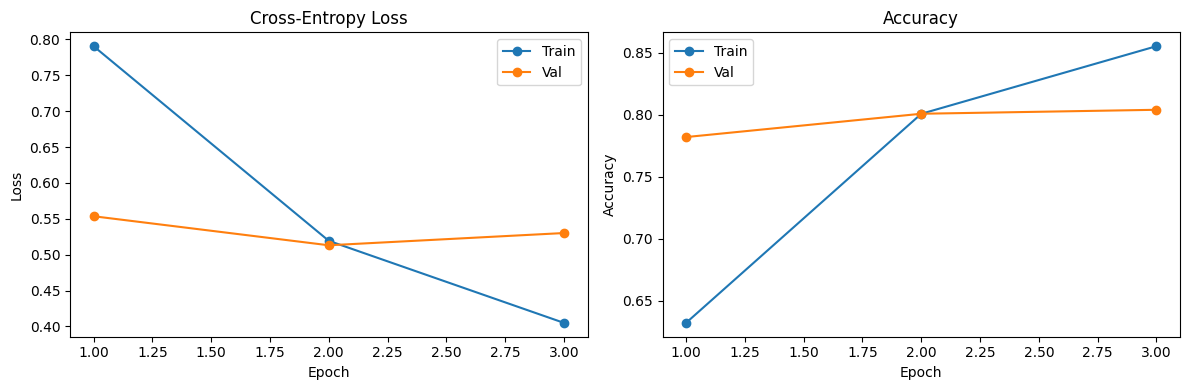

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs_range = range(1, EPOCHS + 1)

axes[0].plot(epochs_range, history["train_loss"], label="Train", marker="o")
axes[0].plot(epochs_range, history["val_loss"],   label="Val",   marker="o")
axes[0].set_title("Cross-Entropy Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], label="Train", marker="o")
axes[1].plot(epochs_range, history["val_acc"],   label="Val",   marker="o")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()


# Save the model

In [ ]:
#model.save_pretrained("./nli_distilbert")
#tokenizer.save_pretrained("./nli_distilbert")
#print("Model and tokenizer saved to ./nli_distilbert")

In [5]:
# To reload later:
from transformers import DistilBertForSequenceClassification, DistilBertTokenizerFast
model = DistilBertForSequenceClassification.from_pretrained("./nli_distilbert")
tokenizer = DistilBertTokenizerFast.from_pretrained("./nli_distilbert")
model = model.to(DEVICE) 

# DEMO

In [6]:
def inf_predict_nli(premise: str, hypothesis: str) -> dict:
    """Returns the predicted label and confidence scores for a premise-hypothesis pair."""
    model.eval()
    enc = tokenizer(
        premise, hypothesis,
        max_length=MAX_LEN,
        padding="max_length",
        truncation=True,
        return_tensors="pt",
    ).to(DEVICE)

    with torch.no_grad():
        logits = model(**enc).logits
    probs = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()

    pred_id   = probs.argmax()
    pred_label = ID2LABEL[pred_id]

    print(f"Premise   : {premise}")
    print(f"Hypothesis: {hypothesis}")
    print(f"Prediction: {pred_label.upper()}  (confidence: {probs[pred_id]:.2%})")
    for i, name in ID2LABEL.items():
        print(f"  {name:15s}: {probs[i]:.2%}")
    return {"label": pred_label, "scores": {ID2LABEL[i]: float(probs[i]) for i in range(NUM_CLASSES)}}


# ── Examples ─────────────────────────────────────────────────────────────
print("=" * 60)
inf_predict_nli("I want an ice cream",
            "The user wants to sleep")
print("=" * 60)
inf_predict_nli("I love the color blue",
            "I love the color red")
print("=" * 60)
inf_predict_nli("George hates football",
            "George loves football")


Premise   : I want an ice cream
Hypothesis: The user wants to sleep
Prediction: CONTRADICTION  (confidence: 69.70%)
  entailment     : 2.90%
  neutral        : 27.40%
  contradiction  : 69.70%
Premise   : I love the color blue
Hypothesis: I love the color red
Prediction: CONTRADICTION  (confidence: 83.82%)
  entailment     : 3.11%
  neutral        : 13.07%
  contradiction  : 83.82%
Premise   : George hates football
Hypothesis: George loves football
Prediction: NEUTRAL  (confidence: 70.92%)
  entailment     : 12.94%
  neutral        : 70.92%
  contradiction  : 16.14%


{'label': 'neutral',
 'scores': {'entailment': 0.12935830652713776,
  'neutral': 0.7092108130455017,
  'contradiction': 0.16143088042736053}}

# Bert training backbone freezing

## Changement de tokenizer

In [20]:
from transformers import BertTokenizerFast
from torch.utils.data import DataLoader, Dataset


MODEL_NAME = "google-bert/bert-base-uncased"
tokenizer  = BertTokenizerFast.from_pretrained(MODEL_NAME)

MAX_LEN = 64  # maximum token length
padding = "longest"

BATCH_SIZE = 64

train_dataset = SNLIDataset(train_data, tokenizer, MAX_LEN)
val_dataset   = SNLIDataset(val_data,   tokenizer, MAX_LEN)
test_dataset  = SNLIDataset(test_data,  tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Number of Batches:\n Train: {len(train_loader)} , Val: {len(val_loader)} , Test: {len(test_loader)}")


Number of Batches:
 Train: 313 , Val: 79 , Test: 79


In [16]:
from transformers import BertForSequenceClassification

# Initializing a model (with random weights) from the google-bert/bert-base-uncased style configuration
model = BertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_CLASSES, id2label=ID2LABEL, label2id=LABEL2ID)

model = model.to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainable parameters: 109,484,547


In [21]:
EPOCHS    = 20
LR        = 1e-4
WARMUP    = 0.5  # fraction of total steps used for warm-up

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

total_steps   = len(train_loader) * EPOCHS
warmup_steps  = int(total_steps * WARMUP)
scheduler     = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

criterion = nn.CrossEntropyLoss()

#Freeze the Backbone
for param in model.bert.parameters():
    param.requires_grad = False

#History
history_2 = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}


for epoch in range(1,EPOCHS+1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    
    history_2["train_loss"].append(train_loss)
    history_2["train_acc"].append(train_acc)
    history_2["val_loss"].append(val_loss)
    history_2["val_acc"].append(val_acc)
    
    print(f"Epoch {epoch}/{EPOCHS}  "
      f"Train loss: {train_loss:.4f}  acc: {train_acc:.4f}  "
      f"Val loss: {val_loss:.4f}  acc: {val_acc:.4f}")
    
test_loss, test_acc = run_epoch(test_loader, training=False)
print(f"Test loss : {test_loss}, Test accuracy : {test_acc}")

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1/20  Train loss: 1.1069  acc: 0.3420  Val loss: 1.0975  acc: 0.3514


  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

...

  0%|          | 0/313 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 20/20  Train loss: 1.0639  acc: 0.4348  Val loss: 1.0487  acc: 0.4674


  0%|          | 0/79 [00:00<?, ?it/s]

Test loss : 1.0518462968826294, Test accuracy : 0.47


In [22]:
# To reload later:
#from transformers import BertForSequenceClassification, BertTokenizerFast
#model = BertForSequenceClassification.from_pretrained("./nli_bert")
#tokenizer = BertTokenizerFast.from_pretrained("./nli_bert")
#model = model.to(DEVICE) 

test_loss, test_acc = run_epoch(test_loader, training=False)
print(f"Test loss : {test_loss}, Test accuracy : {test_acc}")

  0%|          | 0/79 [00:00<?, ?it/s]

Test loss : 1.0518462968826294, Test accuracy : 0.47


In [23]:
#model.save_pretrained("./nli_bert_20epochs")
#tokenizer.save_pretrained("./nli_bert_20epochs")
#print("Model and tokenizer saved to ./nli_bert_20epochs")

Model and tokenizer saved to ./nli_bert_20epochs


# Inférer avec un LLM

### Few shot Prompt engineering technique (PET)

In [24]:
from litellm import completion
from datasets import load_dataset

# Chargement du dataset
snli = load_dataset("snli")
snli = snli.filter(lambda example: example['label'] != -1)

# Mapping des labels
label_map = {0: "entailment", 1: "neutral", 2: "contradiction"}

# Prompts
with open("prompt_context.txt", "r", encoding="utf-8") as f:
    system_prompt = f.read()

user_prompt = "Premise : {premise}\nHypothesis : {hypothesis}\nOutput:"

model_llm = "llama3.1:8b"

def predict_nli(premise, hypothesis):
    full_response = ""
    response = completion(
        model=f"ollama/{model_llm}",
        messages=[
            {"content": system_prompt, "role": "system"},
            {"content": user_prompt.format(premise=premise, hypothesis=hypothesis), "role": "user"}
        ],
        api_base="http://localhost:11434",
        stream=True
    )
    for chunk in response:
        if chunk.choices[0].delta.content:
            full_response += chunk.choices[0].delta.content
    return full_response.strip()

Num_examples = 100

sous_ens = snli["test"].select(range(Num_examples))
# On itére sur un sous-ensemble
list_of_bool = []
for example in sous_ens:
    premise = example["premise"]
    hypothesis = example["hypothesis"]
    true_label = label_map[example["label"]]
    
    predicted = predict_nli(premise, hypothesis)
    if predicted.strip().lower().rstrip(".") == true_label:
        list_of_bool.append(True)
    else:
        list_of_bool.append(False)
        
    #print(f"Prémisse     : {premise}")
    #print(f"Hypothèse    : {hypothesis}")
    #print(f"Vrai label   : {true_label}")
    #print(f"Prédiction   : {predicted}")
    #print("-" * 50)

    
accuracy = sum(list_of_bool) / len(list_of_bool)
print(f"Accuracy of {model_llm} : ", accuracy)

Accuracy of llama3.1:8b :  0.48


### Testing to combine few shot PET with RAR

Rephrase and respond (RAR) is a prompt engineering technique which asks the model to reformulate the question before answering it. It involves adding "Rephrase and extend the question, and respond", or variations as "Rephrase and extend the question, and respond with revelant context". 

See "A Systematic Survey of Prompt Engineering in Large Language Models: Techniques and Applications" published on 5 Feb 2024 for more informations

We suppose it will decrease the results because this technique is more useful for bad prompting, while here we use perfect prompt.

In [28]:
from litellm import completion
from datasets import load_dataset

# Chargement du dataset
snli = load_dataset("snli")
snli = snli.filter(lambda example: example['label'] != -1)

# Mapping des labels
label_map = {0: "entailment", 1: "neutral", 2: "contradiction"}

# Prompts
with open("prompt_context.txt", "r", encoding="utf-8") as f:
    system_prompt = f.read()

user_prompt = "Premise : {premise}\nHypothesis : {hypothesis}\nOutput:"

###Rephrase and Respond PET
RAR = "\nRephrase and expand the question, and respond."
user_prompt = user_prompt + RAR

model_llm = "llama3.1:8b"

def predict_nli(premise, hypothesis):
    full_response = ""
    response = completion(
        model=f"ollama/{model_llm}",
        messages=[
            {"content": system_prompt, "role": "system"},
            {"content": user_prompt.format(premise=premise, hypothesis=hypothesis), "role": "user"}
        ],
        api_base="http://localhost:11434",
        stream=True
    )
    for chunk in response:
        if chunk.choices[0].delta.content:
            full_response += chunk.choices[0].delta.content
    return full_response.strip()

Num_examples = 100

sous_ens = snli["test"].select(range(Num_examples))
# On itére sur un sous-ensemble
list_of_bool = []
for example in sous_ens:
    premise = example["premise"]
    hypothesis = example["hypothesis"]
    true_label = label_map[example["label"]]
    
    predicted = predict_nli(premise, hypothesis)
    if predicted.strip().lower().rstrip(".") == true_label:
        list_of_bool.append(True)
    else:
        list_of_bool.append(False)
        
    #print(f"Prémisse     : {premise}")
    #print(f"Hypothèse    : {hypothesis}")
    #print(f"Vrai label   : {true_label}")
    #print(f"Prédiction   : {predicted}")
    #print("-" * 50)

    
accuracy = sum(list_of_bool) / len(list_of_bool)
print(f"Accuracy of {model_llm} : ", accuracy)

Accuracy of llama3.1:8b :  0.36
